# Investigating the Learning Rate

### Research queation: How does the learning rate affect the way a neural network learns?

#### Hypothesis:

Changing the learning rate will affect how quickly the model learns and whether optimisation remains stable

#### Independent variable:

Learning rate (0.001, 0.01, 0.05)

#### Controlled variables: 

Training data, model architecture, initial parameters, optimiser type and number of epochs.

#### Dependent variables: 

Training loss, learned weight and learned bias

In [1]:
import torch

In [2]:
# Training data
X = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
Y = torch.tensor([[3.0], [5.0], [7.0], [9.0]])

In [3]:
# Learning rates to compare
learning_rates = [0.001, 0.01, 0.05]

In [4]:
# Training configuration
epochs = 1000
loss_fn = torch.nn.MSELoss()

In [5]:
# Store experiment results
results = {}

In [7]:
for lr in learning_rates:

    # Reset the seed so every model starts identically
    torch.manual_seed(42)

    # Initialize a fresh model
    model = torch.nn.Linear(1, 1)

    initial_weight = model.weight.item()
    initial_bias = model.bias.item()

    # Create an optimizer with the current learning rate
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr
    )

    losses = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, Y)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    # Store the results for this learning rate
    results[lr] = {
        "initial_weight": initial_weight,
        "initial_bias": initial_bias,
        "final_weight": model.weight.item(),
        "final_bias": model.bias.item(),
        "final_loss": losses[-1],
        "losses": losses
    }

    print(f"\nLearning rate: {lr}")
    print(f"Final weight: {model.weight.item():.6f}")
    print(f"Final bias: {model.bias.item():.6f}")
    print(f"Final loss: {losses[-1]:.6f}")

    for checkpoint in [10, 50, 100, 500, 1000]:
        print(
            f"Epoch {checkpoint}: "
            f"loss = {losses[checkpoint - 1]:.8f}"
        )



Learning rate: 0.001
Final weight: 1.943459
Final bias: 1.166238
Final loss: 0.004618
Epoch 10: loss = 9.25300026
Epoch 50: loss = 2.41114616
Epoch 100: loss = 0.45390862
Epoch 500: loss = 0.00623092
Epoch 1000: loss = 0.00461819

Learning rate: 0.01
Final weight: 1.996196
Final bias: 1.011184
Final loss: 0.000021
Epoch 10: loss = 0.47472480
Epoch 50: loss = 0.00626176
Epoch 100: loss = 0.00463943
Epoch 500: loss = 0.00042142
Epoch 1000: loss = 0.00002102

Learning rate: 0.05
Final weight: 1.999999
Final bias: 1.000003
Final loss: 0.000000
Epoch 10: loss = 0.00640308
Epoch 50: loss = 0.00191587
Epoch 100: loss = 0.00042396
Epoch 500: loss = 0.00000000
Epoch 1000: loss = 0.00000000


### Conclusion

The learning rate controls the magnitude of parameter updates during gradient descent. A small learning rate can result in slow convergence, while a suitable larger learning rate can reduce the loss more quickly.

However, execessively large learning rates can cause optimisation to become unstable or diverge

The best learning rate depends on the optimisation problem and should be determined experimentally.

### Training Loss Visual Comparison

In [8]:
# Visualisation with matplotlib
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


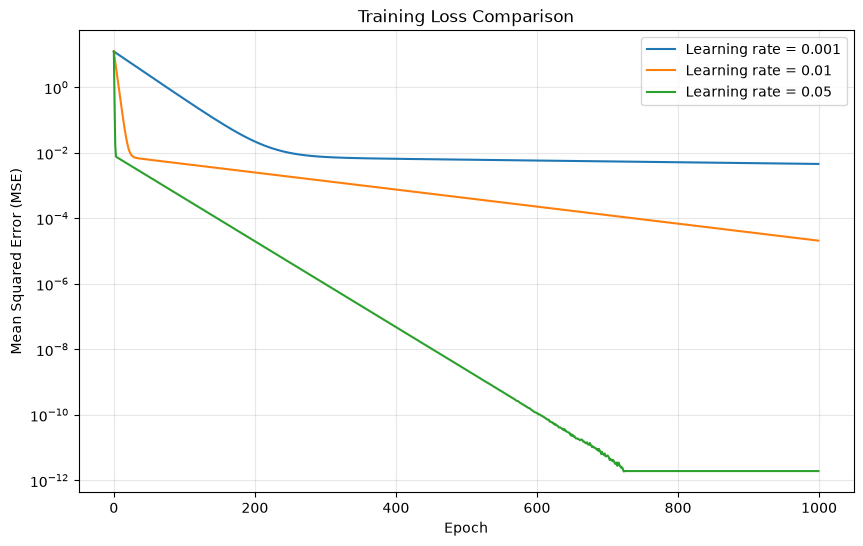

In [9]:
plt.figure(figsize=(10, 6))

for lr, result in results.items():
    plt.plot(
        result["losses"],
        label=f"Learning rate = {lr}"
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")

# Loss values can differ by several orders of magnitude.
plt.yscale("log")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

#### Observations

1. Learning rate 0.001 produced slow convergence. The model continued improving but retained a relatively higher loss after 1000 epochs
2. Learning rate 0.01 produced faster and more consistent convergence
3. Learning rate 0.05 produced the fastest convergence in this experiment, reaching an extremely small loss at approximately epoch 730

**Why logarithmic scaling was used:**

The loss values spanned several orders of magnitude. A logarithmic Y-axis made it easier to compare the training behaviour of all three models.

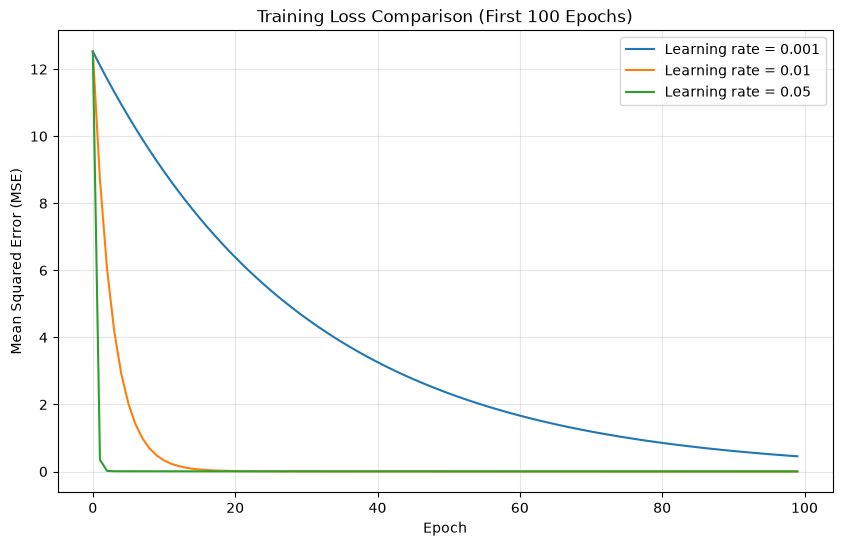

In [10]:
plt.figure(figsize=(10, 6))

for lr, result in results.items():
    plt.plot(
        result["losses"][:100], # Plot only the first 100 epochs for clarity
        label=f"Learning rate = {lr}"
    )

plt.title("Training Loss Comparison (First 100 Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

#### Conclusion

The experiment demonstrates that learning-rate selection influences optimisation speed and stability. A larger learning rate can accelerate convergence when appropriately chosen, but excessively large updates can cause oscillation or divergence.

#### Comparison final model parameters

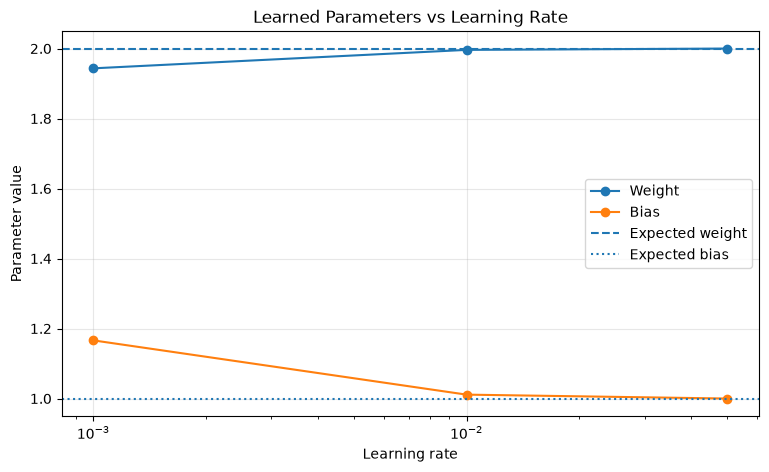

In [11]:
learning_rates = list(results.keys())

weights = [
    results[lr]["final_weight"]
    for lr in learning_rates
]

biases = [
    results[lr]["final_bias"]
    for lr in learning_rates
]

plt.figure(figsize=(9, 5))

plt.plot(learning_rates, weights, marker="o", label="Weight")
plt.plot(learning_rates, biases, marker="o", label="Bias")

plt.axhline(2, linestyle="--", label="Expected weight")
plt.axhline(1, linestyle=":", label="Expected bias")

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Parameter value")
plt.title("Learned Parameters vs Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

#### Comparison final losses

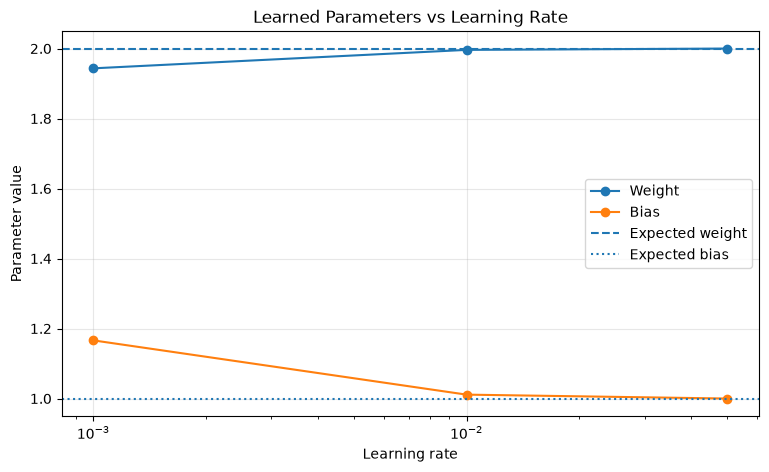

In [12]:
learning_rates = list(results.keys())

weights = [
    results[lr]["final_weight"]
    for lr in learning_rates
]

biases = [
    results[lr]["final_bias"]
    for lr in learning_rates
]

plt.figure(figsize=(9, 5))

plt.plot(learning_rates, weights, marker="o", label="Weight")
plt.plot(learning_rates, biases, marker="o", label="Bias")

plt.axhline(2, linestyle="--", label="Expected weight")
plt.axhline(1, linestyle=":", label="Expected bias")

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Parameter value")
plt.title("Learned Parameters vs Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()